# Notebook 10 – Target Variable Analysis
## Objective
Analyze the target before machine learning. Target analysis helps clarify what the model predicts, detect missing labels or imbalance, and choose appropriate evaluation metrics.

The Telco Customer Churn dataset uses `Churn` as a **classification target**. A reusable numerical regression section is included for other datasets.

## 1. Load dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
sns.set_theme(style="whitegrid")
DATA_PATH = Path("WA_Fn-UseC_-Telco-Customer-Churn.csv")
DATA_PATH = Path( r"C:\Users\ramki\sprint_4\dataset\WA_Fn-UseC_-Telco-Customer-Churn.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"CSV not found at {DATA_PATH.resolve()}. Put the CSV beside this notebook or update DATA_PATH.")
df = pd.read_csv(DATA_PATH)
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Shape:", df.shape)
display(df.head())

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. What is a target variable?
A **target variable** (label or dependent variable) is the outcome a model is trained to predict.
- **Classification:** target is a category, e.g. Churn = Yes/No.
- **Regression:** target is numerical, e.g. price or sales amount.

Understanding the target helps define the prediction task, identify imbalance and data-quality issues, and select evaluation metrics.

## 3. Identify the target

In [3]:
TARGET = "Churn"  # Change if your dataset uses a different target column.
if TARGET in df.columns:
    print("Target:", TARGET)
    print("Data type:", df[TARGET].dtype)
    print("Missing target values:", df[TARGET].isna().sum())
    print("Unique labels:", df[TARGET].nunique(dropna=True))
    display(df[TARGET].value_counts(dropna=False).to_frame("Count"))
else:
    print(f"{TARGET} not found. Available columns:", df.columns.tolist())

Target: Churn
Data type: str
Missing target values: 0
Unique labels: 2


,Count
Churn,
No,5174
Yes,1869


## 4. Classification: class counts and percentages

In [4]:
if TARGET in df.columns:
    counts = df[TARGET].value_counts(dropna=False)
    pct = df[TARGET].value_counts(normalize=True, dropna=False)*100
    display(pd.DataFrame({"Class Count": counts, "Percentage": pct.round(2)}))

,Class Count,Percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


**Interpretation:** Counts show how many rows belong to each class. Percentages allow comparison of class proportions. Class imbalance means one class is more common than another; whether it is a problem depends on the task.

## 5. Visualize class distribution

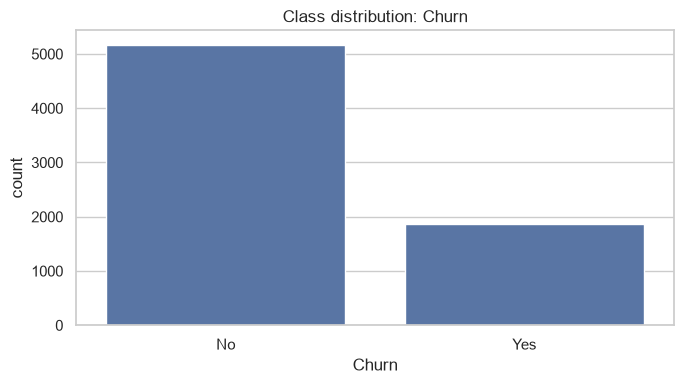

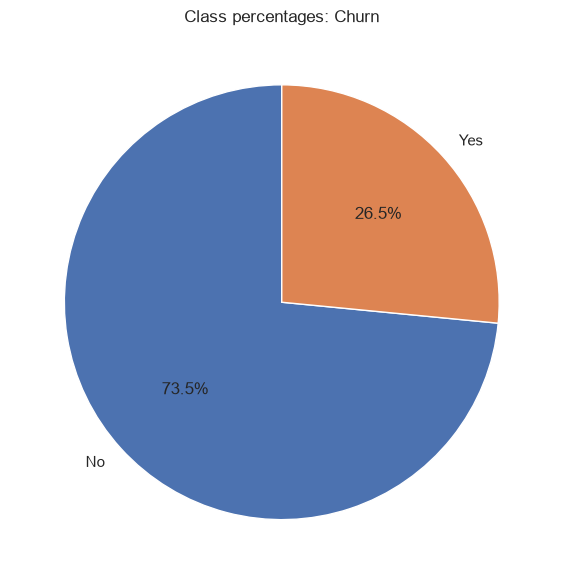

In [5]:
if TARGET in df.columns:
    plt.figure(figsize=(7, 4))
    sns.countplot(data=df, x=TARGET, order=df[TARGET].value_counts().index)
    plt.title(f"Class distribution: {TARGET}")
    plt.tight_layout(); plt.show()

    counts = df[TARGET].value_counts(dropna=False)
    plt.figure(figsize=(6, 6))
    plt.pie(counts.values, labels=counts.index.astype(str), autopct="%1.1f%%", startangle=90)
    plt.title(f"Class percentages: {TARGET}")
    plt.tight_layout(); plt.show()

## 6. Class imbalance ratio

In [6]:
if TARGET in df.columns:
    counts = df[TARGET].value_counts(dropna=True)
    if len(counts) >= 2 and counts.min() > 0:
        print("Majority count:", int(counts.max()))
        print("Minority count:", int(counts.min()))
        print("Majority/minority ratio:", round(counts.max()/counts.min(), 2))
        print("Majority percentage:", round(counts.max()/counts.sum()*100, 2))
        print("Minority percentage:", round(counts.min()/counts.sum()*100, 2))
    else:
        print("At least two non-empty classes are needed.")

Majority count: 5174
Minority count: 1869
Majority/minority ratio: 2.77
Majority percentage: 73.46
Minority percentage: 26.54


## 7. Why class imbalance matters
A model can achieve high accuracy by predicting the majority class and still fail to detect the minority class. For imbalanced classification, consider precision, recall, F1-score, balanced accuracy, and the confusion matrix. Choose metrics based on the cost of false positives and false negatives. If resampling is used, apply it only to training data after splitting.

## 8. Regression target analysis (optional)
The current `Churn` target is categorical, so regression statistics do not apply to it. Set `REGRESSION_TARGET` to a numeric target if using a regression dataset.

In [7]:
REGRESSION_TARGET = None  # Example: "Sales" in a regression dataset.
if REGRESSION_TARGET is not None:
    if REGRESSION_TARGET not in df.columns:
        print("Target column not found.")
    else:
        y = pd.to_numeric(df[REGRESSION_TARGET], errors="coerce").dropna()
        if y.empty:
            print("No valid numeric target values.")
        else:
            print("Mean:", y.mean())
            print("Median:", y.median())
            print("Variance:", y.var())
            print("Standard deviation:", y.std())
            print("Skewness:", y.skew())
            print("Excess kurtosis:", y.kurt())
            print("Min:", y.min(), "Max:", y.max())
            fig, axes = plt.subplots(1, 2, figsize=(12, 4))
            sns.histplot(y, kde=True, ax=axes[0])
            axes[0].set_title("Regression target distribution")
            sns.boxplot(x=y, ax=axes[1])
            axes[1].set_title("Regression target box plot")
            plt.tight_layout(); plt.show()
else:
    print("Regression target section skipped; set REGRESSION_TARGET to a numeric column to run.")

Regression target section skipped; set REGRESSION_TARGET to a numeric column to run.


## 9. Why analyze the target before machine learning?
- Clarifies the prediction objective.
- Reveals missing or unexpected labels.
- Shows class imbalance or numerical skewness.
- Helps select suitable evaluation metrics.
- Provides a baseline for model comparison.
- Prevents misleading conclusions based only on accuracy.

## 10. Findings and conclusion
Answer:
1. What is the target and what does each label mean?
2. What are class counts and percentages?
3. Is the target imbalanced? Quantify it.
4. Which metrics would be useful and why?
5. Are there missing or unexpected target values?

**Conclusion:** Target analysis clarifies the prediction task and helps plan evaluation and preprocessing before building a machine-learning model.